In [ ]:
#end sem practcal examination
set B

In [ ]:
in a reactior with excess A, the reaction A + B -> C has initial concentrations of A = 2.0, B = 1.0, C = 0.0. if x mol/L of C is formed, kc = x/((2-x)(1-x)), which rearranges to Kcx2-(3Kc + 1)+2KC = 0
write a python program that:

a) reads kc using input(), prints the data type of the raw input and converted value, and shows a clear message (no crash) if the text is not a number or if kc<= 0.

In [3]:
# Part (a): Read and validate Kc
kc_text = input("Enter Kc: ")
print("Raw input:", kc_text)
print("Type of raw input:", type(kc_text).__name__)

try:
    kc = float(kc_text)

    if kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        print("Converted Kc:", kc)
        print("Type of converted Kc:", type(kc).__name__)

except ValueError:
    print("Error: Invalid input. Please enter a number.")

Raw input: 10
Type of raw input: str
Converted Kc: 10.0
Type of converted Kc: float


In [6]:
# Part (b): find a, b, c, discriminant, and roots
import math

# Quadratic equation: Kc*x^2 - (3*Kc + 1)*x + 2*Kc = 0
a = kc
b = -(3 * kc + 1)
c = 2 * kc

print("Coefficient a:", a)
print("Coefficient b:", b)
print("Coefficient c:", c)

discriminant = b**2 - 4 * a * c
print("Discriminant:", discriminant)

if discriminant < 0:
    print("No real roots.")
elif discriminant == 0:
    root = -b / (2 * a)
    print("Both roots are equal:", root)
else:
    root1 = (-b + math.sqrt(discriminant)) / (2 * a)
    root2 = (-b - math.sqrt(discriminant)) / (2 * a)
    print("Root 1:", root1)
    print("Root 2:", root2)

Coefficient a: 10.0
Coefficient b: -31.0
Coefficient c: 20.0
Discriminant: 161.0
Root 1: 2.184428877022476
Root 2: 0.9155711229775239


In [7]:
# Part (c): Select the physically meaningful root
# Since B is limiting, the concentration change cannot be negative or exceed 1 mol/L.
roots = []

if discriminant >= 0:
    if discriminant == 0:
        roots.append(root)
    else:
        roots.extend([root1, root2])

physical_roots = [x for x in roots if 0 <= x <= 1]

if physical_roots:
    equilibrium_x = physical_roots[0]
    print("Physically meaningful root(s):", physical_roots)
    print("Selected equilibrium extent x:", equilibrium_x, "mol/L")
else:
    print("No physically meaningful root in the range 0 <= x <= 1.")

Physically meaningful root(s): [0.9155711229775239]
Selected equilibrium extent x: 0.9155711229775239 mol/L


In [8]:
# Part (d): Equilibrium concentrations and conversion of limiting reactant B
initial_A = 2.0
initial_B = 1.0
initial_C = 0.0

if 'equilibrium_x' not in globals():
    print("Error: Select a physically meaningful root in part (c) first.")
else:
    x = equilibrium_x

    equilibrium_A = initial_A - x
    equilibrium_B = initial_B - x
    equilibrium_C = initial_C + x

    conversion_B = (x / initial_B) * 100

    print(f"Equilibrium concentration of A: {equilibrium_A:.3f} mol/L")
    print(f"Equilibrium concentration of B: {equilibrium_B:.3f} mol/L")
    print(f"Equilibrium concentration of C: {equilibrium_C:.3f} mol/L")
    print(f"Conversion of limiting reactant B: {conversion_B:.3f}%")

Equilibrium concentration of A: 1.084 mol/L
Equilibrium concentration of B: 0.084 mol/L
Equilibrium concentration of C: 0.916 mol/L
Conversion of limiting reactant B: 91.557%


In [12]:
import math

# Part (e): Read Kc, calculate conversion, and classify it
# High: conversion >= 70%; Moderate: 40% <=, low: otherwise
kc_text = input("Enter Kc to test (4, 0.5, abc, or -2): ")

try:
    kc = float(kc_text)

    if kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc
        discriminant = b**2 - 4 * a * c

        if discriminant < 0:
            print("No real roots.")
        else:
            root1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root2 = (-b - math.sqrt(discriminant)) / (2 * a)
            physical_roots = [x for x in (root1, root2) if 0 <= x <= 1]

            if not physical_roots:
                print("No physically meaningful root in the range 0 <= x <= 1.")
            else:
                x = physical_roots[0]
                conversion_B = (x / 1.0) * 100

                if conversion_B >= 70:
                    level = "High"
                elif conversion_B >= 40:
                    level = "Moderate"
                else:
                    level = "Low"

                print("Conversion of limiting reactant B: {:.3f}%".format(conversion_B))
                print("Classification: {} (70% or above is High)".format(level))

except ValueError:
    print("Error: Please enter a valid numeric value for Kc.")

Conversion of limiting reactant B: 82.461%
Classification: High (70% or above is High)


In [ ]:
Q2: batch reactor simulation and batch tracking
Part A. hydrogen peroxide decomposition in a batch reactor of first order reaction, dC/dt = -kC, where k is the rate constant and C is the concentration of hydrogen peroxide. use the uler method: C_new = C_old - kc_old.t. take C0 = 1.5 mol/L, k = 0.05 min^-1, t = 2 min, and simulate for 10 minutes.

a) using a for loop, stimulate 20 minutes and print table of time (min), concentration (mol/L), and conversion (%).

In [ ]:
# Part A: Batch reactor simulation using Euler's method
a):
C0 = 1.5          # Initial concentration in mol/L
k = 0.05          # Rate constant in min^-1
dt = 2            # Time step in min
simulation_time = 20

C = C0

print("Time (min)\tConcentration (mol/L)\tConversion (%)")

for time in range(0, simulation_time + 1, dt):
    conversion = (C0 - C) / C0 * 100
    print(f"{time}\t\t{C:.4f}\t\t\t{conversion:.2f}")

    if time < simulation_time:
        C = C - k * C * dt

Time (min)	Concentration (mol/L)	Conversion (%)
0		1.5000			0.00
2		1.3500			10.00
4		1.2150			19.00
6		1.0935			27.10
8		0.9842			34.39
10		0.8857			40.95
12		0.7972			46.86
14		0.7174			52.17
16		0.6457			56.95
18		0.5811			61.26
20		0.5230			65.13


In [14]:
import math

# Part A(b): Exact solution and Euler absolute error at 20 minutes
C0 = 1.5
time = 20
k = 0.05
dt = 2

# Euler concentration at 20 minutes
Euler_C = C0
for _ in range(0, time, dt):
    Euler_C = Euler_C - k * Euler_C * dt

# Exact analytical concentration
exact_C = C0 * math.exp(-k * time)
absolute_error = abs(exact_C - Euler_C)

print("Euler concentration at 20 min: {:.6f} mol/L".format(Euler_C))
print("Exact concentration at 20 min: {:.6f} mol/L".format(exact_C))
print("Absolute error: {:.6f} mol/L".format(absolute_error))

Euler concentration at 20 min: 0.523018 mol/L
Exact concentration at 20 min: 0.551819 mol/L
Absolute error: 0.028802 mol/L


In [15]:
# Part A(c): Repeat simulation until conversion reaches 50% or time reaches 100 min
C0 = 1.5
k = 0.05
dt = 2
maximum_time = 100
target_conversion = 50

C = C0
time = 0
conversion = 0

while conversion < target_conversion and time < maximum_time:
    C = C - k * C * dt
    time += dt
    conversion = (C0 - C) / C0 * 100

print("Time needed: {} min".format(time))
print("Final concentration: {:.4f} mol/L".format(C))
print("Final conversion: {:.2f}%".format(conversion))

Time needed: 14 min
Final concentration: 0.7174 mol/L
Final conversion: 52.17%


In [18]:
# Part B: Count and sum the digits in a reactor tag
reactor_tag = input("Enter reactor tag: ")
print("Entered reactor tag:", reactor_tag)

if reactor_tag == "":
    print("Error: The reactor tag is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in reactor_tag:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("No digits found in the reactor tag.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)

Entered reactor tag: 14
Number of digits: 2
Sum of digits: 5


In [ ]:
Q3). catalyst-pair screening and sampling schedule.

part A: a laboratory has n candidate catalysts, and wants to test r of them together (order does not matter). write a recursive function factorial(n) (remember the base case for 0! = 1). then write a function combinations(n, r) = n /(r!(n-r)!) that uses it. reject invalid input .print the number of possible catalyst sets for n = 7, r = 2, and show the message for n = 4, r = 6

In [19]:
# Q3 Part A: Catalyst combinations
def factorial(number):
    if number == 0:
        return 1
    return number * factorial(number - 1)


def combinations(n, r):
    if n < 0 or r < 0:
        print("Error: n and r must be non-negative integers.")
        return None
    if r > n:
        print(f"Error: Cannot choose r = {r} catalysts from n = {n} catalysts.")
        return None

    return factorial(n) // (factorial(r) * factorial(n - r))


print("Test 1: n = 7, r = 2")
result = combinations(7, 2)
print("Number of possible catalyst sets:", result)

print("\nTest 2: n = 4, r = 6")
combinations(4, 6)

Test 1: n = 7, r = 2
Number of possible catalyst sets: 21

Test 2: n = 4, r = 6
Error: Cannot choose r = 6 catalysts from n = 4 catalysts.


In [ ]:
part B. during a distillation run, samples are taken at times = fibonacci number multiply by 5 minutes. write an iterative function fib_iter(n) that returns a list of the fist n fibonacci numbers, and a recursive function fib_rec(k) that returns the kth fibonacci number (f = 0, f = 1). for n = 9, check that both functions agree and print a table:sample no.| fibonacci tag | sampling time (min).

In [20]:
# Q3 Part B: Fibonacci sampling schedule
def fib_iter(n):
    numbers = []

    for index in range(n):
        if index == 0:
            numbers.append(0)
        elif index == 1:
            numbers.append(1)
        else:
            numbers.append(numbers[index - 1] + numbers[index - 2])

    return numbers


def fib_rec(k):
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 9
iterative_values = fib_iter(n)
recursive_values = [fib_rec(index) for index in range(n)]

print("Functions agree:", iterative_values == recursive_values)
print("Sample No.\tFibonacci Value\tSampling Time (min)")

for index in range(n):
    fibonacci_value = iterative_values[index]
    sampling_time = fibonacci_value * 5
    print(f"{index + 1}\t\t{fibonacci_value}\t\t\t{sampling_time}")

Functions agree: True
Sample No.	Fibonacci Value	Sampling Time (min)
1		0			0
2		1			5
3		1			5
4		2			10
5		3			15
6		5			25
7		8			40
8		13			65
9		21			105


In [ ]:
Q4).kinetics and gas data : pandas and matplotlib 

decompoition hydogen peroxide was studied with two catalyst loadings. the concentration (mol/L) was recorded:

timt_min = [0, 10, 20, 30, 40, 50,] 
run1_mol_L = [1.20, 0.98, 0.80, 0.66, 0.54, 0.44]
run2_mol_L = [1.20, 0.80, 0.54, 0.36, 0.24, 0.16]

a) create a dataframe from this table . save it as kinetics.csv (withoutthe index coloumn) and as kinetics.json. read the csv back and print its shape and data types.

In [21]:
# Q4 Part A: Kinetics data with pandas
import pandas as pd

# Create the kinetics dataframe
time_min = [0, 10, 20, 30, 40, 50]
run1_mol_L = [1.20, 0.98, 0.80, 0.66, 0.54, 0.44]
run2_mol_L = [1.20, 0.80, 0.54, 0.36, 0.24, 0.16]

kinetics_df = pd.DataFrame({
    "time_min": time_min,
    "run1_mol_L": run1_mol_L,
    "run2_mol_L": run2_mol_L
})

# Save the dataframe without the pandas index
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="columns")

# Read the CSV back
kinetics_from_csv = pd.read_csv("kinetics.csv")

print("Shape:", kinetics_from_csv.shape)
print("Data types:")
print(kinetics_from_csv.dtypes)

Shape: (6, 3)
Data types:
time_min        int64
run1_mol_L    float64
run2_mol_L    float64
dtype: object


In [22]:
# Q4 Part B: Mean and standard deviation
run1_mean = kinetics_df["run1_mol_L"].mean()
run1_std = kinetics_df["run1_mol_L"].std()

run2_mean = kinetics_df["run2_mol_L"].mean()
run2_std = kinetics_df["run2_mol_L"].std()

print("Run 1 mean:", run1_mean)
print("Run 1 standard deviation:", run1_std)
print("Run 2 mean:", run2_mean)
print("Run 2 standard deviation:", run2_std)

if run1_std > run2_std:
    print("Run 1 shows more variation.")
else:
    print("Run 2 shows more variation.")

Run 1 mean: 0.77
Run 1 standard deviation: 0.28418303960651836
Run 2 mean: 0.5499999999999999
Run 2 standard deviation: 0.3922754134533542
Run 2 shows more variation.


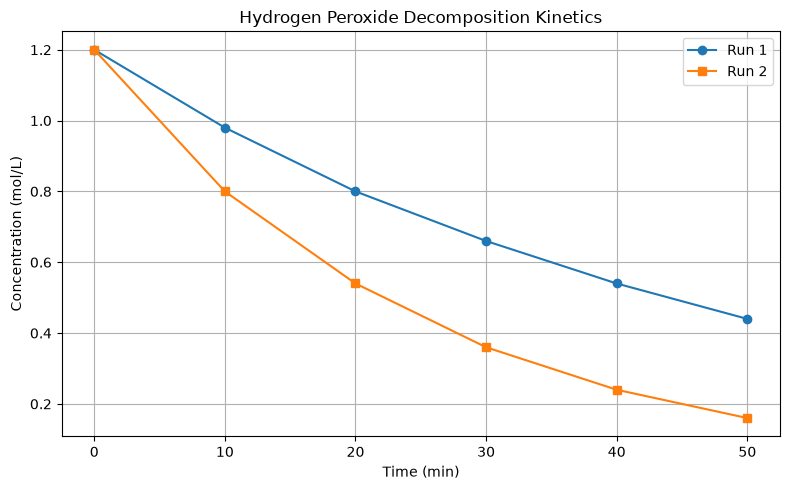

In [23]:
# Q4 Part C: Plot both kinetics runs
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(kinetics_df["time_min"], kinetics_df["run1_mol_L"],
         marker="o", label="Run 1")
plt.plot(kinetics_df["time_min"], kinetics_df["run2_mol_L"],
         marker="s", label="Run 2")

plt.title("Hydrogen Peroxide Decomposition Kinetics")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

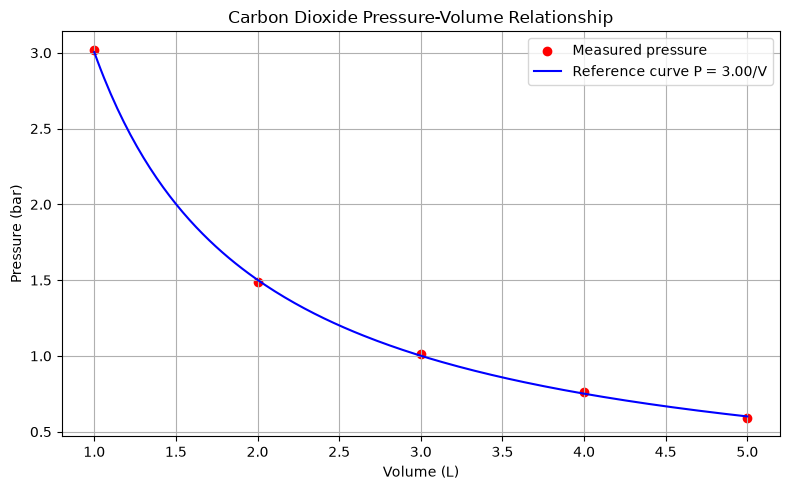

k = 3.0040 bar.L


In [24]:
# Q4 Part D: Pressure-volume relationship
import numpy as np
import matplotlib.pyplot as plt

volume_L = [1, 2, 3, 4, 5]
pressure_bar = [3.02, 1.49, 1.01, 0.76, 0.59]

# Calculate k = mean(P * V)
k_values = [pressure * volume for pressure, volume in zip(pressure_bar, volume_L)]
k = sum(k_values) / len(k_values)

# Generate a smooth reference curve
volume_curve = np.linspace(min(volume_L), max(volume_L), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(volume_L, pressure_bar, color="red", label="Measured pressure")
plt.plot(volume_curve, pressure_curve, color="blue", label=f"Reference curve P = {k:.2f}/V")
plt.title("Carbon Dioxide Pressure-Volume Relationship")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("k = {:.4f} bar.L".format(k))